# 04 · Prédire le clinique à partir des IgE

**Question** : le profil IgE d'un patient contient-il de l'information sur son tableau clinique (anaphylaxie
alimentaire, traitements de l'asthme, de la rhinite, de la dermatite atopique...) **au-delà de ce que disent déjà son
âge, son sexe, la puce utilisée et sa région** ? Et si oui, **quelle partie du profil** porte cette information ?

On ne cherche pas le meilleur score : on compare des modèles **emboîtés** sur les mêmes folds, avec des contrôles
positif et négatif, puis on lit les modèles.

**En bref** (détails et chiffres dans la suite) :

1. Les IgE apportent un gain net et robuste pour l'**anaphylaxie alimentaire** (AUC 0.70 → 0.85), les **symptômes
   cutanés**, la **rhinite** et l'**asthme traités**, la **dermatite atopique traitée** et l'**âge de la première
   anaphylaxie**. Elles n'apportent **rien** pour la sévérité de l'asthme parmi les asthmatiques traités, le traitement
   systémique de la dermatite ou le lieu de vie.
2. **16 comptes** (nombre d'allergènes positifs par famille protéique) font **aussi bien que les 91 IgE** : l'essentiel
   de l'information clinique est dans le *type* de protéines reconnues, pas dans le détail molécule par molécule.
3. Ces familles se lisent comme la clinique les décrit : **albumines 2S** et **légumines 11S** (protéines de stockage
   des graines : arachide, fruits à coque, soja) pour l'anaphylaxie ; **protéases à cystéine** (acariens) et
   **lipocalines** (chat, chien) pour l'asthme ; **β-expansines** (graminées) et **PR-10** (bouleau) pour la rhinite.
4. Le gain **survit à un changement de centre** (leave-one-region-out), alors que le signal de la démographie seule
   s'effondre : il venait surtout des différences entre centres.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats

from acc.allergens import display_name
from acc.data import PROJECT_ROOT, load_raw
from acc.predict import (
    TARGETS,
    common_panel,
    demographic_features,
    labels_for,
    protein_family_features,
)

warnings.filterwarnings("ignore")
RUNS = PROJECT_ROOT / "data" / "processed" / "runs"
FIG = PROJECT_ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# baseline in neutral gray, then the first validated categorical slots
COLORS = {"demo": "#8a8984", "demo+pfam": "#eb6834", "demo+summary": "#1baf7a", "demo+ige": "#2a78d6"}
LABELS = {
    "demo": "démographie (âge, sexe, puce, région)",
    "demo+pfam": "+ familles protéiques (16 comptes)",
    "demo+summary": "+ familles de sources (13 comptes)",
    "demo+ige": "+ 91 IgE (log1p)",
}
from matplotlib.ticker import FixedLocator, NullLocator, FuncFormatter


def log_or_axis(ax, ticks=(0.25, 0.5, 0.7, 1, 1.5, 2, 3, 5, 10, 20, 50)):
    """Log scale with plain-number ticks (no 10^x labels)."""
    ax.set_xscale("log")
    lo, hi = ax.get_xlim()
    ax.xaxis.set_major_locator(FixedLocator([t for t in ticks if lo <= t <= hi]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))


plt.rcParams.update(
    {"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
     "grid.alpha": 0.3, "grid.linewidth": 0.6, "figure.dpi": 110, "font.size": 9}
)

df = load_raw()
panel = common_panel(df)
print(f"{len(df)} patients, panel commun de {len(panel)} allergènes")

4271 patients, panel commun de 91 allergènes


## 1. Les cibles

Aucune variable de sévérité n'existe dans les données : chaque cible est un **proxy construit** à partir d'une variable
clinique codée (voir `acc.predict.TARGETS`). Les patients dont la variable vaut `9` (non renseigné / sans objet) sont
exclus de la cible concernée, d'où des effectifs très différents. Deux contrôles :

- `adult` (âge ≥ 18 ans) : **contrôle positif**, on sait que le profil IgE change avec l'âge ;
- `shuffled` : les labels `food_anaphylaxis` **permutés au sein de chaque puce**. Toute performance au-dessus de 0.5
  viendrait d'une fuite dans le pipeline (ou de la différence de prévalence entre puces, que la démographie capte).

`male` n'est **pas** un contrôle négatif : dans cette cohorte le sexe-ratio dépend fortement de l'âge (garçons chez
les enfants, femmes chez les adultes), donc l'âge seul prédit déjà le sexe (AUC ≈ 0.65).

In [2]:
rows = []
for name, t in TARGETS.items():
    y = labels_for(t, df)
    known = y.notna()
    rows.append(dict(
        target=name, n=int(known.sum()), prevalence=round(float(y.mean()), 3),
        **{f"n_{c}": int((known & (df.Chip_Type == c)).sum()) for c in ["ALEX", "ISAC_V1", "ISAC_V2"]},
        description=t.description,
    ))
targets_table = pd.DataFrame(rows).set_index("target")
targets_table

,n,prevalence,n_ALEX,n_ISAC_V1,n_ISAC_V2,description
target,,,,,,
food_anaphylaxis,1699,0.634,504,668,527,History of food anaphylaxis (Age_of_onsets 1-6...
early_food_anaphylaxis,1077,0.325,315,408,354,Among food-anaphylaxis patients: first episode...
skin_symptoms,1826,0.624,597,723,506,Skin symptoms (1 vs 0; 9 = not relevant is exc...
asthma_treatment,1500,0.402,436,702,362,"Any asthma treatment (codes 1-8, 10) vs none (0)"
asthma_step3,603,0.668,82,384,137,Among treated asthma: GINA step >= 3 (ICS/LABA...
rhinitis_treatment,1313,0.327,346,661,306,Any rhinitis treatment (codes 1-4) vs none (0)
ad_treatment,1582,0.182,449,631,502,Any atopic dermatitis treatment (codes 1-7) vs...
ad_systemic,288,0.333,24,233,31,Among treated atopic dermatitis: systemic (cic...
urban,1291,0.748,260,573,458,Urban (1) vs rural (0) residence


## 2. Protocole

- **Validation** : 5-fold stratifiée (cible × puce) répétée 10 fois, mêmes folds pour tous les modèles et feature sets
  (comparaisons appariées). Tout ce qui est appris (imputation, standardisation, choix de `C`) l'est dans le fold
  d'entraînement uniquement.
- **Feature sets emboîtés** : `demo` (âge, sexe, puce, région, la région étant un proxy du centre recruteur),
  puis `demo` + un résumé interprétable (`pfam` : nombre d'allergènes positifs par famille protéique ; `summary` :
  par famille de sources), puis `demo` + les 91 IgE du panel commun aux trois puces (`log1p`). La puce est toujours
  incluse : ISAC (ISU) et ALEX (kUA/L) ne sont pas sur la même échelle.
- **Modèles** : régression logistique L2 (`C` choisi par CV interne) et gradient boosting (`HistGradientBoosting`,
  hyperparamètres fixes et prudents, non tunés).
- **Tests** : t-test rééchantillonné corrigé de Nadeau & Bengio (2003) sur les différences d'AUC appariées par fold
  (le t-test naïf est anticonservateur car les folds partagent leurs données d'entraînement), puis correction BH sur
  l'ensemble des comparaisons. Les intervalles des figures utilisent la même variance corrigée.
- Calculs lancés sur Chav (`scripts/chav.sh`, job `acc/predict`), résultats dans `data/processed/runs/v2`.

In [3]:
folds = pd.read_csv(RUNS / "v2" / "folds.csv")


def corrected_ci(x, n_train, n_test, level=0.95):
    """Mean and CI of a repeated-CV quantity with the Nadeau-Bengio variance correction."""
    x = np.asarray(x)
    k = len(x)
    se = np.sqrt((1 / k + n_test / n_train) * x.var(ddof=1))
    t = stats.t.ppf(0.5 + level / 2, k - 1)
    return x.mean(), x.mean() - t * se, x.mean() + t * se


def summarize(g, metric="auc"):
    m, lo, hi = corrected_ci(g[metric], g.n_train.mean(), g.n_test.mean())
    return pd.Series(dict(mean=m, lo=lo, hi=hi))


summ = folds.groupby(["target", "model", "features"]).apply(summarize, include_groups=False).reset_index()
auc_table = summ.assign(cell=summ["mean"].map("{:.3f}".format)).pivot_table(
    index=["target", "model"], columns="features", values="cell", aggfunc="first"
)[["demo", "demo+pfam", "demo+summary", "demo+ige", "pfam"]]
auc_table

features                        demo demo+pfam demo+summary demo+ige   pfam
target                 model                                               
ad_systemic            hgb     0.907     0.898        0.886    0.905  0.800
                       logreg  0.885     0.885        0.894    0.872  0.751
ad_treatment           hgb     0.805     0.844        0.848    0.844  0.803
                       logreg  0.802     0.842        0.845    0.843  0.837
adult                  hgb     0.742     0.794        0.808    0.831  0.710
                       logreg  0.730     0.763        0.784    0.793  0.687
asthma_step3           hgb     0.573     0.554        0.551    0.500  0.516
                       logreg  0.605     0.588        0.579    0.564  0.550
asthma_treatment       hgb     0.751     0.792        0.780    0.807  0.735
                       logreg  0.758     0.796        0.797    0.790  0.741
early_food_anaphylaxis hgb     0.787     0.822        0.823    0.824  0.722
                       logreg  0.781     0.800        0.812    0.798  0.739
food_anaphylaxis       hgb     0.704     0.851        0.838    0.840  0.807
                       logreg  0.721     0.796        0.783    0.794  0.758
male                   hgb     0.652     0.672        0.671    0.679  0.606
                       logreg  0.640     0.658        0.658    0.659  0.617
rhinitis_treatment     hgb     0.636     0.723        0.724    0.694  0.699
                       logreg  0.620     0.730        0.732    0.736  0.728
shuffled               hgb     0.525     0.531        0.537    0.507  0.528
                       logreg  0.537     0.540        0.537    0.535  0.541
skin_symptoms          hgb     0.702     0.792        0.787    0.795  0.722
                       logreg  0.714     0.760        0.751    0.773  0.712
urban                  hgb     0.764     0.764        0.768    0.764  0.534
                       logreg  0.772     0.772        0.775    0.756  0.554

## 3. Les IgE apportent-elles de l'information au-delà de la démographie ?

AUC moyenne (10 × 5 folds) et intervalle à 95 % corrigé, par cible et par feature set. Gradient boosting à gauche,
régression logistique à droite.

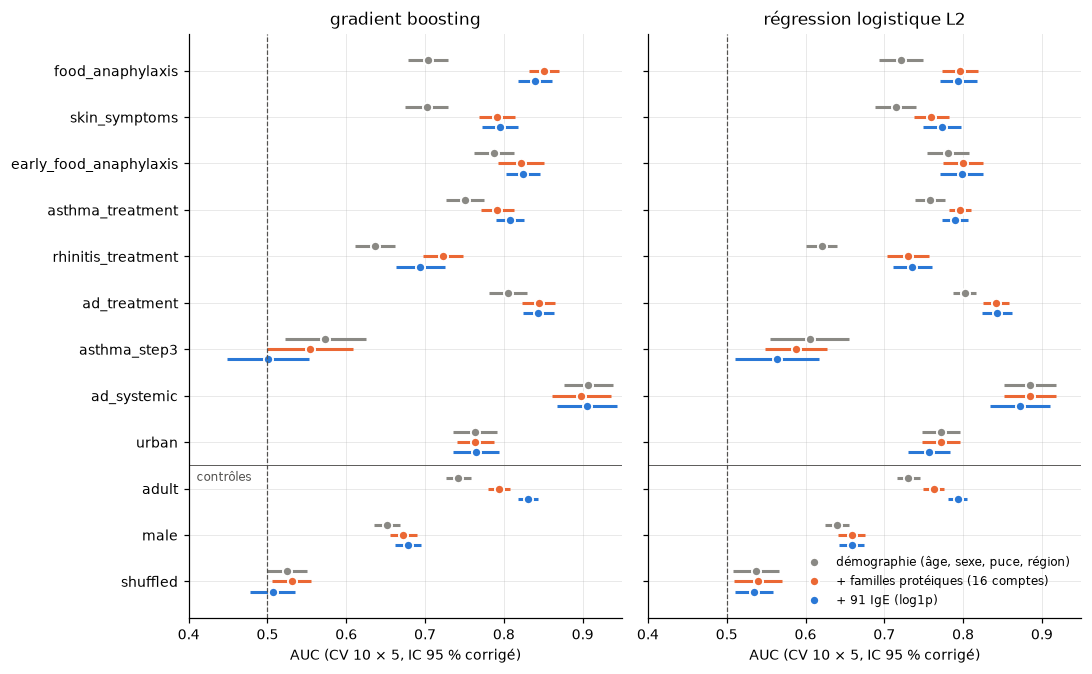

In [4]:
CLINICAL = ["food_anaphylaxis", "skin_symptoms", "early_food_anaphylaxis", "asthma_treatment",
            "rhinitis_treatment", "ad_treatment", "asthma_step3", "ad_systemic", "urban"]
CONTROLS = ["adult", "male", "shuffled"]
order = CLINICAL + CONTROLS
sets = ["demo", "demo+pfam", "demo+ige"]

fig, axes = plt.subplots(1, 2, figsize=(10, 6.2), sharey=True)
for ax, model in zip(axes, ["hgb", "logreg"]):
    s = summ[summ.model == model].set_index(["target", "features"])
    for j, fs in enumerate(sets):
        ypos = np.arange(len(order)) + (j - 1) * 0.22
        m = [s.loc[(t, fs), "mean"] for t in order]
        lo = [s.loc[(t, fs), "lo"] for t in order]
        hi = [s.loc[(t, fs), "hi"] for t in order]
        ax.hlines(ypos, lo, hi, color=COLORS[fs], lw=2)
        ax.plot(m, ypos, "o", ms=6, color=COLORS[fs], mec="white", mew=1.2, label=LABELS[fs])
    ax.axvline(0.5, color="#52514e", lw=0.8, ls="--")
    ax.axhline(len(CLINICAL) - 0.5, color="#52514e", lw=0.6)
    ax.set_title({"hgb": "gradient boosting", "logreg": "régression logistique L2"}[model])
    ax.set_xlabel("AUC (CV 10 × 5, IC 95 % corrigé)")
    ax.set_xlim(0.4, 0.95)
axes[0].set_yticks(range(len(order)), order)
axes[0].invert_yaxis()
axes[0].text(0.41, len(CLINICAL) - 0.1, "contrôles", fontsize=8, color="#52514e", va="bottom")
axes[1].legend(loc="lower right", fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIG / "04_auc_by_target.png", dpi=200, bbox_inches="tight")
plt.show()

Gain d'AUC apporté par les IgE par rapport à la démographie seule (différences appariées par fold, IC 95 % corrigé),
et significativité après correction BH.

In [5]:
def paired_gain(model, cand, ref):
    out = []
    for t in order:
        g = folds[(folds.target == t) & (folds.model == model)]
        w = g.pivot_table(index=["repeat", "fold"], columns="features", values="auc")
        d = (w[cand] - w[ref]).to_numpy()
        m, lo, hi = corrected_ci(d, g.n_train.mean(), g.n_test.mean())
        se = (hi - m) / stats.t.ppf(0.975, len(d) - 1)
        p = 2 * stats.t.sf(abs(m / se), len(d) - 1)
        out.append(dict(target=t, model=model, comparison=f"{cand} - {ref}", gain=m, lo=lo, hi=hi, p=p))
    return out


gains = pd.DataFrame(
    [r for m in ["hgb", "logreg"]
     for cand, ref in [("demo+ige", "demo"), ("demo+pfam", "demo"), ("demo+ige", "demo+pfam")]
     for r in paired_gain(m, cand, ref)]
)
gains["q"] = stats.false_discovery_control(gains["p"], method="bh")
view = gains[gains.model == "hgb"].copy()
view["gain [IC 95 %]"] = view.apply(lambda r: f"{r.gain:+.3f} [{r.lo:+.3f}, {r.hi:+.3f}]", axis=1)
view["q"] = view["q"].map(lambda q: f"{q:.1e}" if q < 1e-3 else f"{q:.3f}")
view.pivot_table(index="target", columns="comparison", values=["gain [IC 95 %]", "q"], aggfunc="first").loc[order]

gain [IC 95 %]                           \
comparison                      demo+ige - demo     demo+ige - demo+pfam   
target                                                                     
food_anaphylaxis        +0.136 [+0.109, +0.163]  -0.011 [-0.027, +0.005]   
skin_symptoms           +0.093 [+0.069, +0.117]  +0.003 [-0.011, +0.017]   
early_food_anaphylaxis  +0.037 [+0.012, +0.061]  +0.002 [-0.018, +0.023]   
asthma_treatment        +0.057 [+0.036, +0.078]  +0.016 [-0.002, +0.033]   
rhinitis_treatment      +0.058 [+0.018, +0.097]  -0.029 [-0.059, +0.001]   
ad_treatment            +0.039 [+0.012, +0.066]  -0.000 [-0.019, +0.018]   
asthma_step3            -0.073 [-0.134, -0.012]  -0.053 [-0.101, -0.006]   
ad_systemic             -0.002 [-0.036, +0.032]  +0.007 [-0.024, +0.038]   
urban                   +0.001 [-0.027, +0.028]  +0.001 [-0.023, +0.024]   
adult                   +0.089 [+0.074, +0.103]  +0.037 [+0.026, +0.047]   
male                    +0.027 [+0.010, +0.044]  +0.006 [-0.009, +0.022]   
shuffled                -0.018 [-0.058, +0.021]  -0.024 [-0.056, +0.008]   

                                                              q  \
comparison                     demo+pfam - demo demo+ige - demo   
target                                                            
food_anaphylaxis        +0.147 [+0.125, +0.169]         2.3e-12   
skin_symptoms           +0.090 [+0.070, +0.110]         6.0e-09   
early_food_anaphylaxis  +0.034 [+0.010, +0.058]           0.012   
asthma_treatment        +0.041 [+0.021, +0.061]         8.0e-06   
rhinitis_treatment      +0.087 [+0.058, +0.115]           0.013   
ad_treatment            +0.039 [+0.015, +0.064]           0.013   
asthma_step3            -0.019 [-0.068, +0.029]           0.044   
ad_systemic             -0.009 [-0.043, +0.025]           0.997   
urban                   +0.000 [-0.022, +0.023]           0.997   
adult                   +0.052 [+0.039, +0.064]         1.3e-14   
male                    +0.021 [+0.005, +0.036]           0.007   
shuffled                +0.006 [-0.027, +0.038]           0.537   

                                                              
comparison             demo+ige - demo+pfam demo+pfam - demo  
target                                                        
food_anaphylaxis                      0.317          2.9e-16  
skin_symptoms                         0.837          1.2e-10  
early_food_anaphylaxis                0.955            0.014  
asthma_treatment                      0.153          5.7e-04  
rhinitis_treatment                    0.121          9.5e-07  
ad_treatment                          0.997            0.007  
asthma_step3                          0.060            0.597  
ad_systemic                           0.837            0.816  
urban                                 0.997            0.997  
adult                               6.0e-08          5.1e-10  
male                                  0.597            0.021  
shuffled                              0.272            0.907

**Lecture.**

- **Les contrôles se comportent comme attendu.** `adult` : les IgE ajoutent +0.09 d'AUC à la démographie (le profil
  change avec l'âge). `shuffled` : AUC ≈ 0.51–0.54 pour tous les feature sets, aucun gain des IgE (q > 0.5). Le léger
  excès au-dessus de 0.5 vient de la différence de prévalence entre puces, conservée par la permutation intra-puce
  (l'AUC intra-puce de `shuffled` est 0.50–0.53) : pas de fuite.
- **Anaphylaxie alimentaire** : 0.704 [0.678, 0.729] avec la démographie, **0.851 [0.832, 0.870]** avec les familles
  protéiques, 0.840 avec les 91 IgE (gradient boosting). Le gain est le même au sein de chaque puce (ALEX 0.62 → 0.81,
  ISAC v1 0.72 → 0.85, ISAC v2 0.76 → 0.88), donc il ne vient pas d'un effet puce. AP 0.81 → 0.91 pour une
  prévalence de 0.63.
- **Gains plus modestes mais nets** (q < 0.02) : symptômes cutanés (+0.09), rhinite traitée (+0.09 à +0.11),
  asthme traité (+0.04 à +0.06), dermatite atopique traitée (+0.04), anaphylaxie avant 2 ans parmi les
  anaphylactiques (+0.03, l'âge porte déjà l'essentiel).
- **Pas de gain** : `asthma_step3` (palier GINA ≥ 3 parmi les asthmatiques traités) reste proche du hasard
  (AUC 0.50–0.60) ; **le profil IgE dit qui a de l'asthme, pas sa sévérité**. `ad_systemic` est très bien prédit par
  la démographie seule (0.91 : centre, période et puce, la dupilumab étant récente), les IgE n'ajoutent rien. `urban`
  est entièrement porté par la région.
- **Le résumé suffit** : `demo+ige` contre `demo+pfam` n'est significatif pour aucune cible clinique au seuil
  q < 0.05 avec le gradient boosting (le seul écart net est sur le contrôle `adult`, où des molécules précises marquent
  l'âge). Le gradient boosting fait mieux que la logistique sur les IgE brutes (seuils de positivité, interactions).

## 4. Quelles familles protéiques ? Un modèle lisible

Le résumé `pfam` (nombre d'allergènes positifs par famille protéique, 16 variables) fait presque aussi bien que les
91 IgE. On l'ajuste donc en régression logistique classique sur **toutes** les données de chaque cible, avec âge,
puce et région en covariables, pour lire des odds ratios : **OR par allergène positif supplémentaire dans la
famille**. C'est une analyse d'association (pas de validation croisée ici : le pouvoir prédictif de ce modèle est
mesuré en section 3), et les IC de Wald ne sont pas corrigés pour les 16 familles.

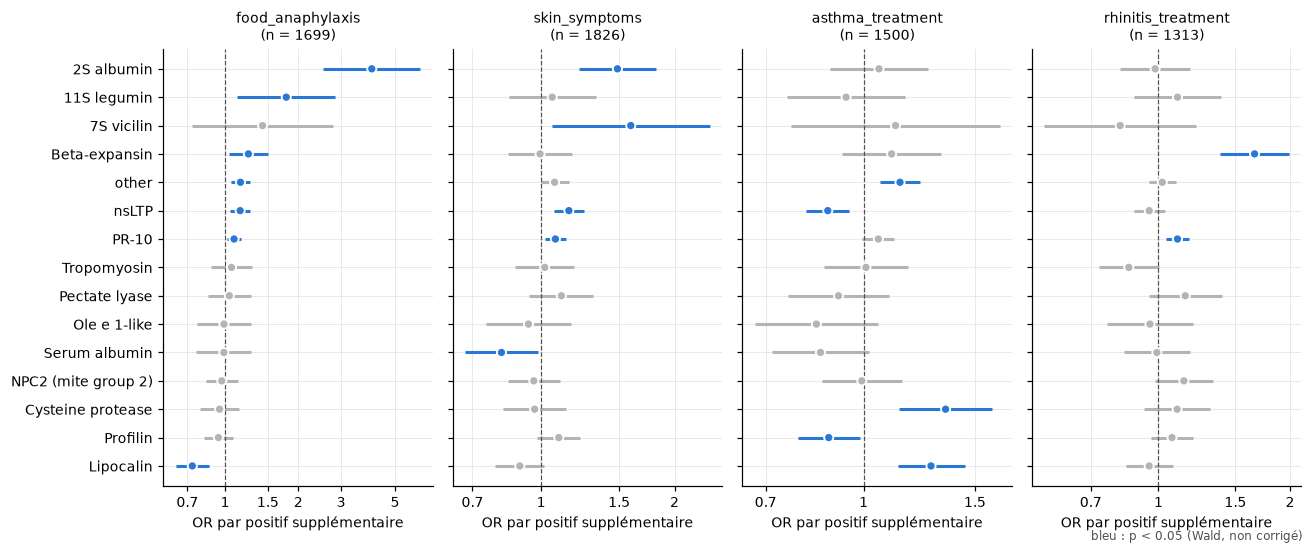

In [6]:
def pfam_logit(target):
    y_all = labels_for(TARGETS[target], df)
    sub, y = df[y_all.notna()], y_all.dropna().to_numpy().astype(int)
    X = protein_family_features(sub, panel).drop(columns=["npos_total", "pfam_storage_all"])
    X = X.loc[:, X.std() > 0]
    d = demographic_features(sub).drop(columns=["Gender"])
    d["Age"] = d["Age"] / 10
    for prefix in ["chip_", "region_"]:  # one reference level per one-hot block
        d = d.drop(columns=[c for c in d if c.startswith(prefix)][0])
    Z = sm.add_constant(pd.concat([X, d], axis=1))
    ok = Z.notna().all(axis=1).to_numpy()
    fit = sm.Logit(y[ok], Z[ok]).fit(disp=0)
    ci = np.exp(fit.conf_int().loc[X.columns])
    return pd.DataFrame({"OR": np.exp(fit.params[X.columns]), "lo": ci[0], "hi": ci[1],
                         "p": fit.pvalues[X.columns], "n": ok.sum()})


PFAM_TARGETS = ["food_anaphylaxis", "skin_symptoms", "asthma_treatment", "rhinitis_treatment"]
pfam = {t: pfam_logit(t) for t in PFAM_TARGETS}
fam_order = pfam["food_anaphylaxis"].sort_values("OR").index

fig, axes = plt.subplots(1, len(PFAM_TARGETS), figsize=(12, 5), sharey=True)
for ax, t in zip(axes, PFAM_TARGETS):
    r = pfam[t].reindex(fam_order)
    y = np.arange(len(r))
    sig = r.p < 0.05
    ax.hlines(y, r.lo, r.hi, color=np.where(sig, "#2a78d6", "#b5b4ae"), lw=2)
    ax.scatter(r.OR, y, s=36, c=np.where(sig, "#2a78d6", "#b5b4ae"), edgecolors="white", linewidths=1.2, zorder=3)
    ax.axvline(1, color="#52514e", lw=0.8, ls="--")
    log_or_axis(ax)
    ax.set_title(f"{t}\n(n = {int(r.n.iloc[0])})", fontsize=9)
    ax.set_xlabel("OR par positif supplémentaire")
axes[0].set_yticks(range(len(fam_order)), [f.removeprefix("pfam_") for f in fam_order])
fig.text(0.99, 0.01, "bleu : p < 0.05 (Wald, non corrigé)", ha="right", fontsize=8, color="#52514e")
fig.tight_layout()
fig.savefig(FIG / "04_protein_family_odds_ratios.png", dpi=200, bbox_inches="tight")
plt.show()

**Lecture** (OR par allergène positif supplémentaire de la famille, ajusté sur âge, puce, région et les autres familles).

- **Anaphylaxie alimentaire** : chaque **albumine 2S** positive multiplie la cote par **4.0** [2.5, 6.4], chaque
  **légumine 11S** par 1.8 [1.1, 2.8]. Les nsLTP (1.15) et PR-10 (1.09) jouent peu une fois les protéines de stockage
  prises en compte, et les **lipocalines** (phanères animaux) sont associées à *moins* d'anaphylaxie (0.73) : elles
  marquent un profil respiratoire. C'est la lecture classique du diagnostic moléculaire (protéines stables, résistantes
  à la chaleur et à la digestion → réactions systémiques ; protéines labiles → syndrome oral), retrouvée ici sans
  l'avoir imposée.
- **Asthme traité** : **protéases à cystéine** (Der p 1, Der f 1 : acariens) 1.35 et **lipocalines** (Fel d 4,
  Can f 1 : chat, chien) 1.28, soit les allergènes perannuels de l'intérieur. Profilines et nsLTP sont légèrement
  négatives.
- **Rhinite traitée** : **β-expansines** (Phl p 1, groupe 1 des graminées) 1.66 et **PR-10** (Bet v 1) 1.10 : les
  pollens saisonniers.
- Les symptômes cutanés suivent le profil de l'anaphylaxie alimentaire (2S, 7S, nsLTP), ce qui est cohérent avec la
  façon dont la variable semble codée (9 = « sans objet », surtout renseignée chez les patients avec anaphylaxie).

Ces OR sont des associations dans une cohorte hospitalière, pas des effets causaux, et un compte de familles suppose
que chaque positif supplémentaire compte autant (linéarité sur l'échelle logit), ce qui reste une approximation.

## 5. Quels allergènes ? Screening ajusté

Une régression logistique par couple (cible, allergène), sur les patients dont la puce mesure l'allergène (les 241
colonnes, pas seulement le panel commun) : `y ~ positif(allergène) + âge + âge² + puce + région`, puis le même modèle
**+ log(1 + nombre d'autres allergènes positifs)**. Le second ajustement sépare un **marqueur spécifique** d'un simple
reflet de la polysensibilisation : sans lui, presque tous les allergènes sortent avec OR > 1 parce que les patients
anaphylactiques sont plus sensibilisés en général. BH par cible et par ajustement ; allergènes avec au moins 20
positifs et 20 négatifs.

In [7]:
screen = pd.read_csv(RUNS / "screen3" / "screen.csv")
n_sig = screen.groupby(["target", "adjustment"])["q"].apply(lambda q: int((q < 0.05).sum())).unstack()
n_sig.columns.name = "nb d'allergènes q < 0.05"
n_sig

nb d'allergènes q < 0.05,demo,demo+npos
target,,
ad_systemic,1,1
ad_treatment,79,14
asthma_step3,0,0
asthma_treatment,70,22
early_food_anaphylaxis,30,24
food_anaphylaxis,134,20
rhinitis_treatment,64,1
skin_symptoms,114,19
urban,0,0


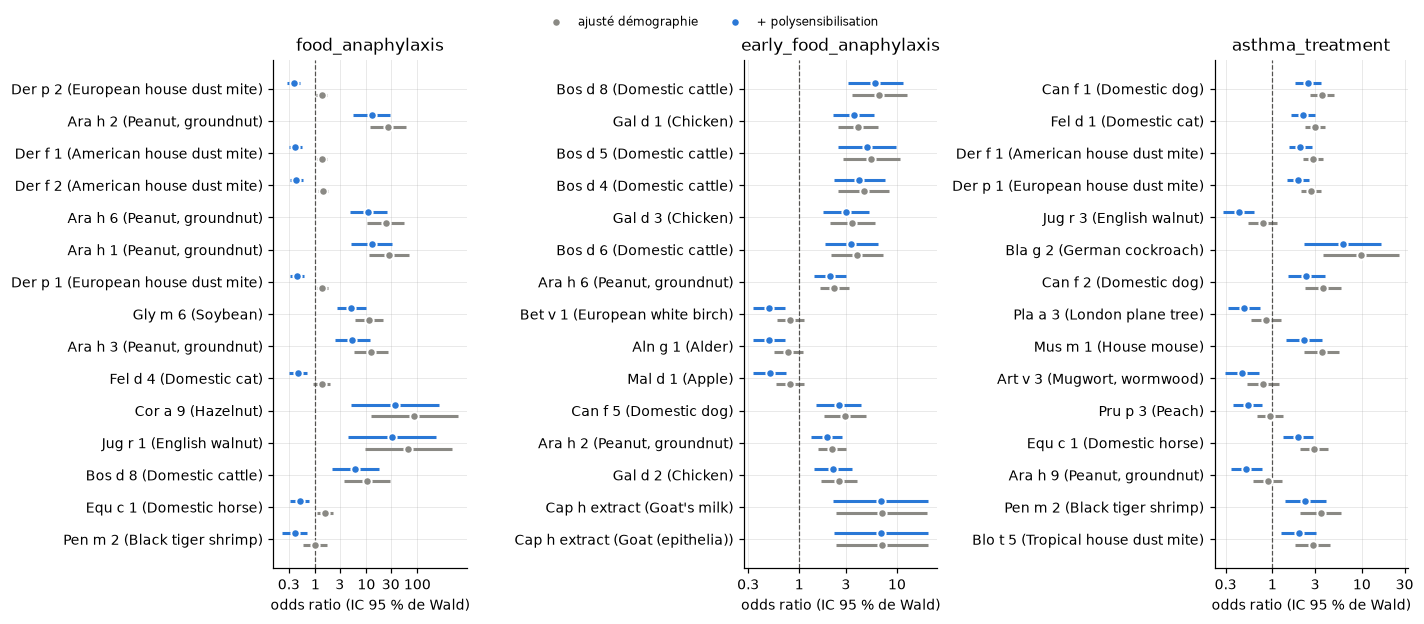

In [8]:
def screen_forest(target, top=15, ax=None):
    s = screen[screen.target == target].set_index(["allergen", "adjustment"])
    adj = screen[(screen.target == target) & (screen.adjustment == "demo+npos")].nsmallest(top, "p")
    names = adj.allergen.tolist()[::-1]
    y = np.arange(len(names))
    for off, a, color in [(-0.18, "demo", "#8a8984"), (0.18, "demo+npos", "#2a78d6")]:
        r = s.xs(a, level="adjustment").reindex(names)
        ax.hlines(y + off, r.ci_low, r.ci_high, color=color, lw=2)
        ax.scatter(r.odds_ratio, y + off, s=30, color=color, edgecolors="white", linewidths=1.2, zorder=3,
                   label={"demo": "ajusté démographie", "demo+npos": "+ polysensibilisation"}[a])
    ax.axvline(1, color="#52514e", lw=0.8, ls="--")
    log_or_axis(ax, ticks=(0.3, 1, 3, 10, 30, 100))
    ax.set_yticks(y, [display_name(a) for a in names])
    ax.set_xlabel("odds ratio (IC 95 % de Wald)")
    ax.set_title(target)


fig, axes = plt.subplots(1, 3, figsize=(13, 5.5))
for ax, t in zip(axes, ["food_anaphylaxis", "early_food_anaphylaxis", "asthma_treatment"]):
    screen_forest(t, ax=ax)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=8, frameon=False, bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
fig.savefig(FIG / "04_allergen_screen.png", dpi=200, bbox_inches="tight")
plt.show()

In [9]:
cols = ["allergen", "family", "n_pos", "prev_pos", "prev_neg", "odds_ratio", "ci_low", "ci_high", "q"]
top = (screen[(screen.adjustment == "demo+npos") & (screen.q < 0.05)]
       .sort_values(["target", "p"]).groupby("target").head(6)[["target"] + cols])
top.round(3)

,target,allergen,family,n_pos,prev_pos,prev_neg,odds_ratio,ci_low,ci_high,q
88,ad_systemic,Equ_c_3,animal dander,24,0.708,0.299,32.479,4.968,212.332,0.025
347,ad_treatment,Ole_e_9,tree pollen,100,0.630,0.152,3.820,2.234,6.532,0.000
348,ad_treatment,Asp_f_6,molds / yeasts,56,0.589,0.167,4.947,2.449,9.995,0.001
349,ad_treatment,Act_d_1,plant food,157,0.446,0.153,2.642,1.694,4.122,0.001
350,ad_treatment,Mus_m_1,animal dander,123,0.537,0.152,2.872,1.766,4.670,0.001
351,ad_treatment,Fel_d_4,animal dander,187,0.455,0.146,2.449,1.611,3.724,0.001
352,ad_treatment,Bet_v_2,tree pollen,167,0.186,0.182,0.388,0.236,0.636,0.004
865,asthma_treatment,Can_f_1,animal dander,286,0.657,0.342,2.529,1.811,3.532,0.000
866,asthma_treatment,Fel_d_1,animal dander,569,0.564,0.303,2.197,1.628,2.965,0.000
867,asthma_treatment,Der_f_1,mites,488,0.570,0.321,2.051,1.536,2.738,0.000


**Lecture.**

- L'ajustement sur la polysensibilisation **divise par 3 à 60 le nombre d'allergènes « significatifs »** (anaphylaxie
  134 → 20, rhinite 64 → 1) : la plupart des associations brutes ne disent que « ce patient est plus sensibilisé ».
  Bet v 1 ou Phl p 1, OR ≈ 3 contre l'anaphylaxie en brut, tombent à 1.0.
- **Anaphylaxie alimentaire** : il reste les **protéines de stockage de l'arachide** (Ara h 2, Ara h 1, Ara h 6,
  OR ≈ 11–13 ; 98 % des patients positifs pour Ara h 2 ont un antécédent d'anaphylaxie contre 57 % des négatifs) et du
  **soja** (Gly m 6), et les **acariens** et phanères animaux deviennent *inversement* associés (OR ≈ 0.4) : à
  sensibilisation totale égale, un profil tourné vers les acariens est un profil respiratoire.
- **Anaphylaxie avant 2 ans** (parmi les anaphylactiques) : **lait** (caséine Bos d 8, OR 6.0 ; Bos d 4, 5, 6) et
  **œuf** (Gal d 1, ovomucoïde), les allergies du nourrisson ; les PR-10 (Bet v 1, Mal d 1) vont avec une première
  anaphylaxie plus tardive.
- **Asthme traité** : chien (Can f 1), chat (Fel d 1), acariens (Der p 1, Der f 1), blatte (Bla g 2) ; à l'inverse,
  plusieurs **nsLTP alimentaires** (Jug r 3, Pru p 3, Pla a 3, Art v 3) sont associées à *moins* d'asthme traité :
  le « syndrome LTP » de l'adulte méditerranéen est surtout alimentaire.
- **Rhinite traitée** : seul Phl p 1 (graminées) reste après ajustement ; **sévérité de l'asthme** (`asthma_step3`) :
  aucun allergène, ni brut ni ajusté.

Ces q-values corrigent pour les ~200 allergènes testés par cible, pas pour le nombre de cibles ; les OR très grands
(Ara h 2) ont des IC larges car presque tous les positifs sont des cas.

## 6. Ce que le gradient boosting utilise : importance par permutation

Pour le modèle `demo+ige` (gradient boosting), baisse de l'AUC sur le fold de test quand on permute une variable
(5-fold × 2 répétitions, 3 permutations par variable). Mesure sur données tenues à part, donc pas d'optimisme
d'entraînement ; mais des variables corrélées se partagent l'importance (permuter `Ara h 2` seul laisse `Ara h 6`).

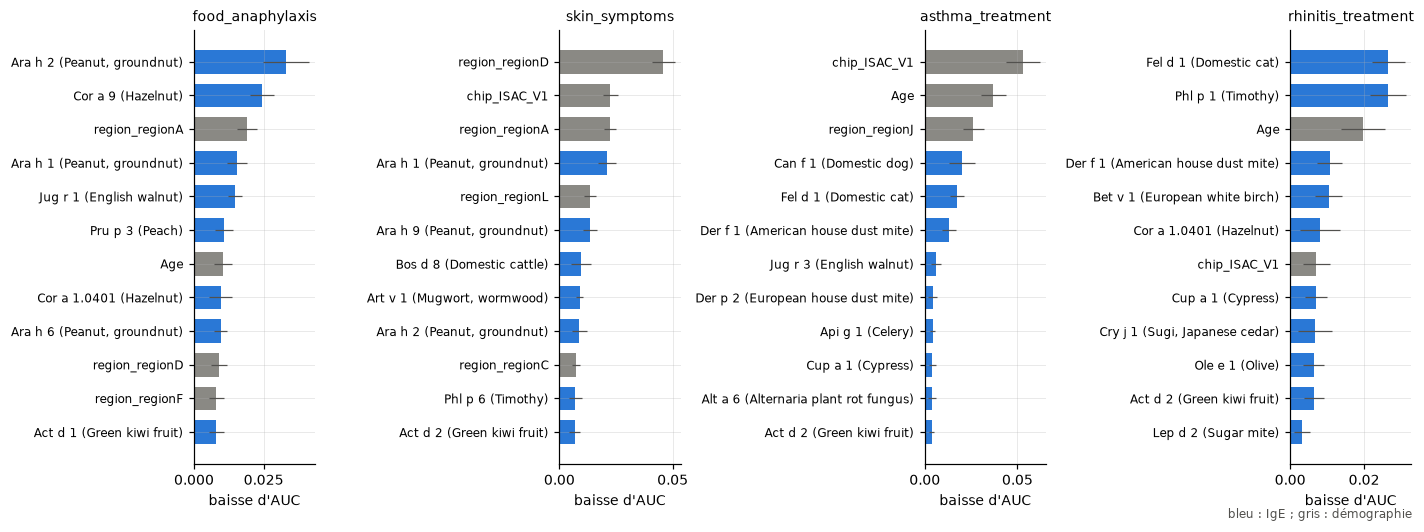

In [10]:
imp = pd.read_csv(RUNS / "imp" / "importance.csv")
IMP_TARGETS = ["food_anaphylaxis", "skin_symptoms", "asthma_treatment", "rhinitis_treatment"]
fig, axes = plt.subplots(1, 4, figsize=(13, 4.8))
for ax, t in zip(axes, IMP_TARGETS):
    g = imp[imp.target == t].nlargest(12, "mean")[::-1]
    labels = [display_name(f.removeprefix("ige_")) if f.startswith("ige_") else f for f in g.feature]
    is_ige = g.feature.str.startswith("ige_")
    ax.barh(range(len(g)), g["mean"], xerr=1.96 * g["se"], height=0.7,
            color=np.where(is_ige, "#2a78d6", "#8a8984"), error_kw=dict(lw=0.8, ecolor="#52514e"))
    ax.set_yticks(range(len(g)), labels, fontsize=8)
    ax.set_title(t, fontsize=9)
    ax.set_xlabel("baisse d'AUC")
fig.text(0.99, 0.01, "bleu : IgE ; gris : démographie", ha="right", fontsize=8, color="#52514e")
fig.tight_layout()
fig.savefig(FIG / "04_permutation_importance.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Le gain survit-il à un changement de centre ? Leave-one-region-out

La région est un proxy du centre recruteur (12 laboratoires hospitaliers). On entraîne sur toutes les régions sauf
une et on teste sur la région tenue à part (régions avec au moins 100 patients et 10 cas pour la cible). Les
indicatrices de région sont retirées des features : une région jamais vue n'a pas de coefficient. C'est un test plus
dur que la CV aléatoire : les pratiques de codage, la période et la puce changent d'un centre à l'autre.

In [11]:
tr = pd.read_csv(RUNS / "transport" / "transport.csv")
wide = tr.pivot_table(index=["target", "model", "region"], columns="features", values="auc")
wide["n_test"] = tr.groupby(["target", "model", "region"])["n_test"].first()
gain = (wide["demo+ige"] - wide["demo"]).groupby(level=[0, 1])
transport_summary = pd.DataFrame({
    "régions": gain.size(),
    "AUC demo": wide["demo"].groupby(level=[0, 1]).mean(),
    "AUC demo+ige": wide["demo+ige"].groupby(level=[0, 1]).mean(),
    "gain moyen": gain.mean(),
    "gain min": gain.min(),
    "régions avec gain > 0": (gain.apply(lambda g: (g > 0).sum())),
})
transport_summary.round(3)

régions  AUC demo  AUC demo+ige  gain moyen  \
target                 model                                                 
ad_treatment           hgb           5     0.576         0.680       0.104   
                       logreg        5     0.484         0.697       0.214   
asthma_treatment       hgb           7     0.620         0.728       0.108   
                       logreg        7     0.614         0.720       0.106   
early_food_anaphylaxis hgb           4     0.714         0.774       0.060   
                       logreg        4     0.746         0.739      -0.007   
food_anaphylaxis       hgb           7     0.535         0.779       0.244   
                       logreg        7     0.562         0.712       0.150   
rhinitis_treatment     hgb           5     0.571         0.668       0.097   
                       logreg        5     0.499         0.725       0.226   
skin_symptoms          hgb           9     0.517         0.660       0.143   
                       logreg        9     0.572         0.659       0.088   

                               gain min  régions avec gain > 0  
target                 model                                    
ad_treatment           hgb        0.066                      5  
                       logreg     0.148                      5  
asthma_treatment       hgb        0.011                      7  
                       logreg     0.005                      7  
early_food_anaphylaxis hgb        0.025                      4  
                       logreg    -0.041                      2  
food_anaphylaxis       hgb        0.088                      7  
                       logreg    -0.050                      6  
rhinitis_treatment     hgb        0.074                      5  
                       logreg     0.066                      5  
skin_symptoms          hgb       -0.207                      8  
                       logreg    -0.119                      7

In [12]:
wide.xs("hgb", level="model").round(3)

features                         demo  demo+ige  demo+summary    ige  n_test
target                 region                                               
ad_treatment           regionA  0.470     0.662         0.640  0.656     237
                       regionC  0.548     0.642         0.658  0.648     322
                       regionI  0.571     0.637         0.587  0.620     107
                       regionJ  0.632     0.729         0.730  0.561     182
                       regionL  0.660     0.731         0.775  0.685     172
asthma_treatment       regionA  0.504     0.683         0.657  0.666     296
                       regionC  0.615     0.736         0.733  0.700     310
                       regionF  0.660     0.756         0.722  0.716     236
                       regionI  0.571     0.712         0.667  0.697     118
                       regionJ  0.690     0.700         0.644  0.692     164
                       regionL  0.600     0.713         0.704  0.726     134
                       regionM  0.701     0.796         0.721  0.792     112
early_food_anaphylaxis regionC  0.733     0.808         0.814  0.728     219
                       regionF  0.651     0.754         0.759  0.628     148
                       regionJ  0.737     0.762         0.734  0.675     143
                       regionL  0.734     0.772         0.804  0.707     154
food_anaphylaxis       regionA  0.481     0.734         0.682  0.717     213
                       regionC  0.524     0.783         0.739  0.784     314
                       regionF  0.421     0.729         0.721  0.735     298
                       regionI  0.653     0.741         0.717  0.716     115
                       regionJ  0.509     0.829         0.824  0.824     195
                       regionL  0.512     0.838         0.812  0.836     184
                       regionM  0.646     0.799         0.752  0.782     171
rhinitis_treatment     regionA  0.559     0.633         0.661  0.617     279
                       regionC  0.575     0.667         0.744  0.649     295
                       regionF  0.565     0.670         0.705  0.661     179
                       regionJ  0.502     0.584         0.608  0.599     171
                       regionM  0.654     0.787         0.870  0.724     113
skin_symptoms          regionA  0.488     0.571         0.544  0.572     273
                       regionB  0.565     0.745         0.637  0.764     138
                       regionC  0.549     0.660         0.625  0.675     235
                       regionD  0.602     0.395         0.671  0.447     149
                       regionF  0.489     0.694         0.666  0.696     362
                       regionI  0.500     0.592         0.645  0.598     120
                       regionJ  0.517     0.755         0.727  0.752     170
                       regionL  0.382     0.769         0.785  0.792     184
                       regionM  0.561     0.760         0.762  0.753     174

**Lecture du transport.**

- **Anaphylaxie alimentaire** : sur une région jamais vue, la démographie seule tombe à 0.42–0.65 (son AUC de 0.70 en
  CV aléatoire venait surtout de la région, c'est-à-dire du centre) ; avec les IgE le modèle reste entre **0.73 et
  0.84**, gain positif dans **7 régions sur 7** (gradient boosting, gain moyen +0.24).
- Même constat, gain positif dans toutes les régions testées, pour l'asthme traité, la rhinite traitée et la
  dermatite atopique traitée.
- **Symptômes cutanés** : 8 régions sur 9 seulement ; dans la région D (la plus grande, 1 100 patients), le modèle
  IgE fait *moins bien que le hasard* (0.40). La variable est probablement codée différemment selon les centres :
  c'est la cible la moins fiable de la liste.

## 8. Conclusions

**Ce que les résultats montrent** (10 × 5 CV, tests corrigés, BH ; transport sur 4 à 9 régions) :

- le profil IgE apporte une information clinique propre, au-delà de l'âge, du sexe, de la puce et du centre, pour
  l'anaphylaxie alimentaire surtout, et plus modestement pour les traitements de l'asthme, de la rhinite et de la
  dermatite atopique ;
- cette information est **résumable** : 16 comptes par famille protéique suffisent, et ils se lisent avec les
  catégories du diagnostic moléculaire (protéines de stockage pour l'anaphylaxie, acariens et animaux pour l'asthme,
  pollens pour la rhinite) ;
- le gain se **transporte** d'un centre à l'autre ;
- le profil IgE ne dit **rien sur la sévérité de l'asthme** une fois l'asthme traité.

**Ce que les résultats suggèrent** : un score « nombre d'albumines 2S / légumines 11S positives » serait un marqueur
simple du risque d'anaphylaxie alimentaire dans cette population ; à valider comme tel (calibration, seuils).

**Limites** :

- toutes les cibles sont des **proxies** construits sur des variables souvent manquantes (30 à 60 % de `9` selon la
  variable) ; les patients renseignés ne sont pas un échantillon aléatoire et la part renseignée varie selon le centre ;
- **cohorte hospitalière** à forte proportion d'allergies alimentaires sévères : aucune extrapolation à la population
  générale ;
- analyse **transversale** : on « prédit » un antécédent ou un traitement à partir d'IgE mesurées au même moment, pas
  un événement futur ;
- seulement le **panel commun** de 91 allergènes dans les modèles (les 132 allergènes propres à ALEX ne servent qu'au
  screening) ; hyperparamètres du gradient boosting non tunés ;
- les **cofacteurs** (`General_cofactors`) ne sont pas utilisés : le code 10 (« rongeurs ») concerne 918 patients, ce
  qui ressemble plus à une erreur de codage qu'à la réalité, et 0 mélange probablement « aucun » et « inconnu ».